# Práctica Evaluativa 2 · Notebook 1: Auto MPG
### Regresión lineal simple, regresión lineal múltiple y ANOVA de una vía

| | |
|---|---|
| **Universidad** | Universidad Cooperativa de Colombia |
| **Programa** | Ingeniería de Software |
| **Asignatura** | Analítica de Datos |
| **Docente** | Luis Miguel Gómez Meneses |
| **Práctica** | Práctica Evaluativa 2: regresión lineal, comparación de medias y clasificación |
| **Autor(es)** | Santiago Rodriguez Jimenez y Alexander Mejia Ospina |
| **Base de datos** | `auto-mpg.csv` (suministrada por el docente) |

**Pregunta central:** ¿qué características permiten predecir `mpg` y cuánto mejora la predicción al incorporar varias variables?

**Ruta del notebook:**
1. Librerías
2. Carga de los datos
3. Comprensión de los datos
4. Calidad de los datos y decisiones de preparación
5. División 60/20/20 e imputación
6. Exploración de relaciones
7. Regresión lineal simple (3 modelos)
8. Regresión lineal múltiple (2 modelos)
9. Comparación de los cinco modelos en validación
10. Evaluación final en prueba
11. Gráficos del modelo recomendado
12. ANOVA de una vía (4, 6 y 8 cilindros)
13. Conclusión general

## 1. Librerías

Se usan `pandas` y `numpy` para manejar los datos, `matplotlib` y `seaborn` para los gráficos, `scikit-learn` para dividir los datos, entrenar las regresiones y calcular las métricas, y `scipy.stats` para las pruebas del ANOVA.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from scipy import stats

sns.set_theme(style='whitegrid')

SEMILLA = 42   # semilla fija para que la división siempre dé los mismos registros

El archivo `auto-mpg.csv` se sube directamente a Colab (panel de archivos de la izquierda, botón de subir) antes de ejecutar la celda. En local, el CSV debe estar en la misma carpeta del notebook.

Se conserva el nombre original de la columna `model-year` (con guion), tal como viene en el archivo.

In [4]:
df = pd.read_csv('auto-mpg.csv')   # el CSV se sube al panel de archivos de Colab (o va junto al notebook en local)
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (398, 7)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70


## 3. Comprensión de los datos

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    396 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model-year    398 non-null    int64  
dtypes: float64(4), int64(3)
memory usage: 21.9 KB


El archivo tiene **398 registros y 7 columnas**, todas numéricas. Cada fila es un vehículo (un modelo de un año específico) con su rendimiento y sus características técnicas. Lo único que llama la atención de entrada es que `horsepower` tiene 396 valores no nulos, o sea que le faltan 2.

| Variable | Significado | Rol en la práctica |
|---|---|---|
| `mpg` | Millas por galón. Más alto = el carro rinde más el combustible | **Variable objetivo** |
| `cylinders` | Número de cilindros del motor | Predictor candidato y grupos del ANOVA |
| `displacement` | Cilindrada del motor (pulgadas cúbicas en la fuente original) | Predictor candidato |
| `horsepower` | Potencia del motor en caballos de fuerza | Predictor candidato |
| `weight` | Peso del vehículo (libras en la fuente original) | Predictor candidato |
| `acceleration` | Tiempo que tarda en acelerar (segundos de 0 a 60 mph). Más alto = más lento | Predictor candidato |
| `model-year` | Año del modelo con dos dígitos (70 = 1970, 82 = 1982) | Predictor candidato |

## 4. Calidad de los datos

Se revisan faltantes, duplicados, rangos e inconsistencias antes de decidir si hace falta algún tratamiento.

In [6]:
print('Valores faltantes por columna:')
print(df.isna().sum())
print('\nFilas duplicadas:', df.duplicated().sum())

Valores faltantes por columna:
mpg             0
cylinders       0
displacement    0
horsepower      2
weight          0
acceleration    0
model-year      0
dtype: int64

Filas duplicadas: 0


In [7]:
# Registros con horsepower vacío
df[df['horsepower'].isna()]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
32,25.0,4,98.0,NaN,2046,19.0,71
126,21.0,6,200.0,NaN,2875,17.0,74


In [8]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.51,7.82,9.0,17.50,23.0,29.00,46.6
cylinders,398.0,5.45,1.70,3.0,4.00,4.0,8.00,8.0
displacement,398.0,193.43,104.27,68.0,104.25,148.5,262.00,455.0
horsepower,396.0,104.19,38.40,46.0,75.00,92.0,125.00,230.0
weight,398.0,2970.42,846.84,1613.0,2223.75,2803.5,3608.00,5140.0
acceleration,398.0,15.57,2.76,8.0,13.82,15.5,17.18,24.8
model-year,398.0,76.01,3.70,70.0,73.00,76.0,79.00,82.0


In [9]:
print('Valores únicos de cylinders:', sorted(df['cylinders'].unique().tolist()))
print('Rango de model-year:', df['model-year'].min(), 'a', df['model-year'].max())
print('¿Hay valores cero o negativos?', (df.drop(columns='model-year') <= 0).any().any())

print('\nRegistros por número de cilindros:')
print(df['cylinders'].value_counts().sort_index())

Valores únicos de cylinders: [3, 4, 5, 6, 8]
Rango de model-year: 70 a 82
¿Hay valores cero o negativos? False

Registros por número de cilindros:
cylinders
3      4
4    204
5      3
6     84
8    103
Name: count, dtype: int64


In [10]:
# Conteo de atípicos con la regla del IQR (solo como diagnóstico)
atipicos = {}
for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    atipicos[col] = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()

pd.Series(atipicos, name='atípicos (IQR)')

,atípicos (IQR)
mpg,1
cylinders,0
displacement,0
horsepower,10
weight,0
acceleration,7
model-year,0


### Decisiones de preparación

| Revisión | Qué se encontró | Decisión |
|---|---|---|
| **Faltantes** | 2 valores vacíos en `horsepower` (0,5 % de los datos) | **Imputar con la mediana de `horsepower` calculada solo con entrenamiento**, después de dividir. No se eliminan las filas porque son muy pocas y así los cinco modelos usan exactamente los mismos registros. Se usa la mediana y no la media porque `horsepower` es asimétrica a la derecha y tiene algunos valores altos. |
| **Duplicados** | 0 filas duplicadas | No se hace nada. |
| **Tipos** | Todo es numérico, no hay texto como `?` mezclado | No se hace conversión. `horsepower` aparece como `float` solo por los vacíos. |
| **Rangos** | Todos los valores son positivos y razonables para carros (peso entre 1.613 y 5.140 lb, potencia entre 46 y 230 hp, años de 70 a 82) | No hay inconsistencias que corregir. |
| **Cilindros raros** | Hay 4 carros de 3 cilindros y 3 de 5 cilindros | Son vehículos reales poco comunes, no errores. Se quedan en las regresiones; solo se excluyen del ANOVA, como pide la guía. |
| **Atípicos** | 10 en `horsepower`, 7 en `acceleration` y 1 en `mpg` según el IQR | **Se conservan.** Son carros reales (muy potentes, muy lentos o muy eficientes) y la guía pide no eliminar observaciones solo por ser extremas. |
| **Escalado** | Las variables tienen escalas distintas | No se escalan. La regresión lineal por mínimos cuadrados no lo necesita y así los coeficientes se interpretan en las unidades originales. |

## 5. División de los datos: 60 % entrenamiento, 20 % validación, 20 % prueba

La división se hace **una sola vez** con la semilla 42. Primero se separa el 60 % para entrenamiento y queda un 40 % temporal; ese 40 % se parte a la mitad para validación y prueba. Los mismos registros se usan en los cinco modelos de regresión.

In [11]:
train, temp = train_test_split(df, test_size=0.40, random_state=SEMILLA)
val, test = train_test_split(temp, test_size=0.50, random_state=SEMILLA)

train = train.copy()
val = val.copy()
test = test.copy()

print(f'Entrenamiento: {len(train)} registros ({len(train)/len(df):.0%})')
print(f'Validación:    {len(val)} registros ({len(val)/len(df):.0%})')
print(f'Prueba:        {len(test)} registros ({len(test)/len(df):.0%})')

print('\nFaltantes de horsepower en cada conjunto:')
print('Entrenamiento:', train['horsepower'].isna().sum(),
      '| Validación:', val['horsepower'].isna().sum(),
      '| Prueba:', test['horsepower'].isna().sum())

Entrenamiento: 238 registros (60%)
Validación:    80 registros (20%)
Prueba:        80 registros (20%)

Faltantes de horsepower en cada conjunto:
Entrenamiento: 1 | Validación: 0 | Prueba: 1


### Imputación de `horsepower`

La mediana se calcula **solo con entrenamiento** y ese mismo valor se usa para llenar los vacíos en los tres conjuntos. Así no se filtra información de validación ni de prueba hacia el modelo.

In [12]:
mediana_hp = train['horsepower'].median()
print('Mediana de horsepower en entrenamiento:', mediana_hp)

for conjunto in (train, val, test):
    conjunto['horsepower'] = conjunto['horsepower'].fillna(mediana_hp)

print('Faltantes después de imputar -> entrenamiento:', train.isna().sum().sum(),
      '| validación:', val.isna().sum().sum(), '| prueba:', test.isna().sum().sum())

objetivo = 'mpg'
predictores = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model-year']

Mediana de horsepower en entrenamiento: 95.0
Faltantes después de imputar -> entrenamiento: 0 | validación: 0 | prueba: 0


## 6. Exploración de relaciones (solo con entrenamiento)

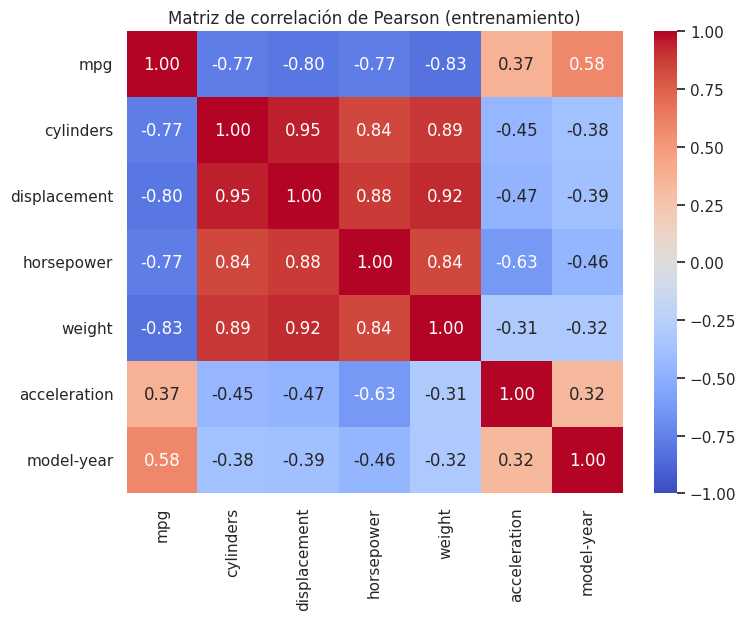

In [13]:
corr = train.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación de Pearson (entrenamiento)')
plt.show()

In [14]:
print('Correlación de cada predictor con mpg (entrenamiento):')
corr['mpg'].drop('mpg').sort_values().round(3)

Correlación de cada predictor con mpg (entrenamiento):


,mpg
weight,-0.826
displacement,-0.805
horsepower,-0.773
cylinders,-0.769
acceleration,0.369
model-year,0.582


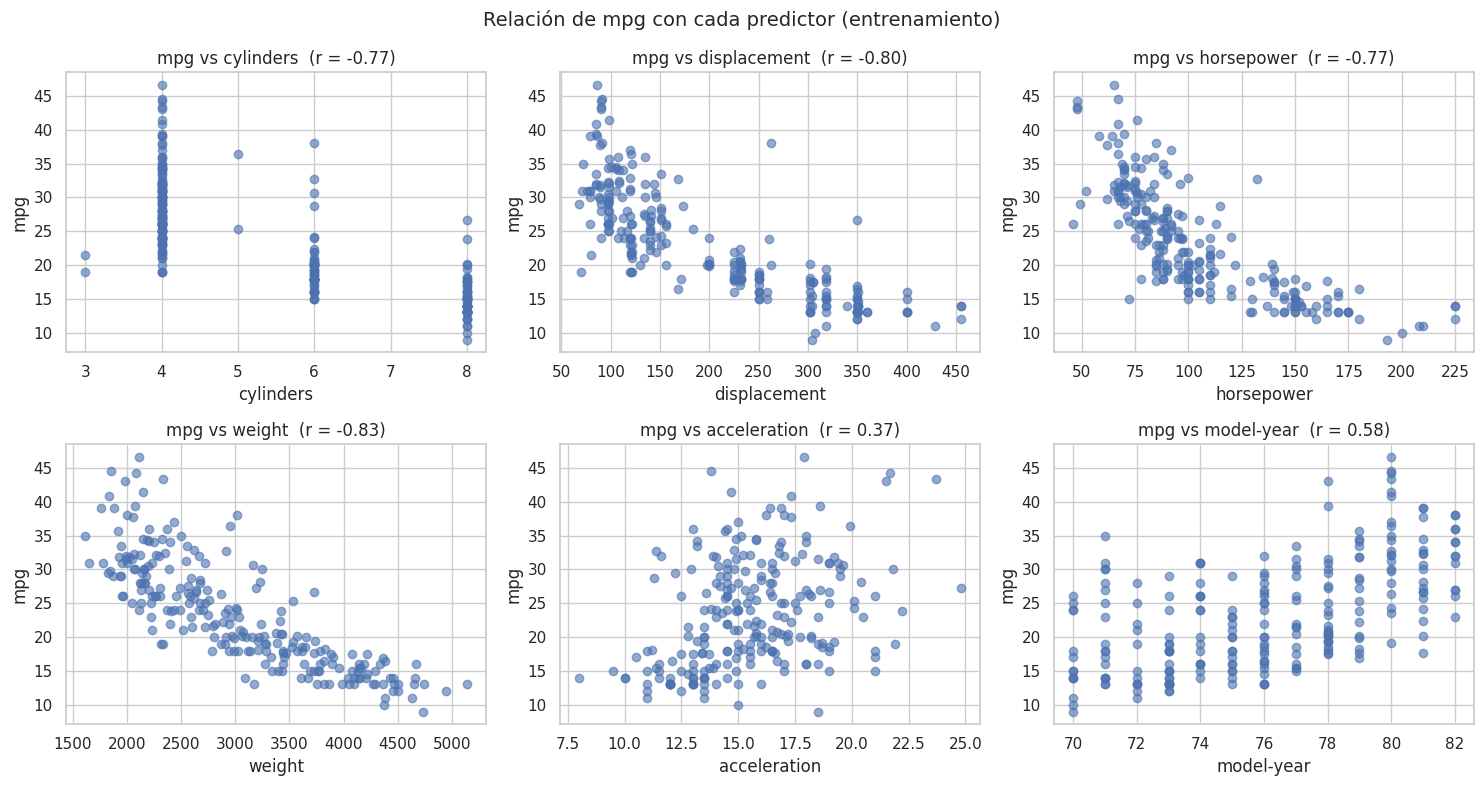

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), predictores):
    ax.scatter(train[col], train['mpg'], alpha=0.6)
    ax.set_xlabel(col)
    ax.set_ylabel('mpg')
    ax.set_title(f'mpg vs {col}  (r = {corr.loc[col, "mpg"]:.2f})')

plt.suptitle('Relación de mpg con cada predictor (entrenamiento)', fontsize=14)
plt.tight_layout()
plt.show()

**Qué muestran la matriz y los gráficos:**

- **Dirección.** `weight` (r = −0,83), `displacement` (−0,80), `horsepower` (−0,77) y `cylinders` (−0,77) tienen relación **negativa** y fuerte con `mpg`: carros más pesados y con motores más grandes rinden menos. `model-year` tiene relación **positiva** moderada (0,58): los carros más nuevos rinden más. `acceleration` tiene una relación positiva débil (0,37) y con mucha dispersión.
- **Forma.** En `weight`, `displacement` y `horsepower` la nube no es una recta perfecta, se ve **curva**: el `mpg` cae rápido en los carros livianos y la caída se va aplanando en los pesados. Eso ya avisa que un modelo lineal va a tener errores sistemáticos en los extremos. `cylinders` solo toma 5 valores, por eso se ven columnas de puntos.
- **Información semejante (redundancia).** `cylinders`, `displacement`, `horsepower` y `weight` están muy correlacionadas entre sí (por ejemplo `cylinders`–`displacement` = 0,95 y `displacement`–`weight` = 0,92). Las cuatro miden prácticamente lo mismo: el tamaño del carro y de su motor. En cambio, `model-year` tiene correlación baja con ellas (entre −0,32 y −0,46), así que aporta información diferente.

**Pregunta de reflexión: ¿por qué una correlación alta con `mpg` no garantiza la mejor predicción ni demuestra causalidad?**

Porque la correlación solo mide qué tan bien se alinean dos variables **en línea recta** y **en estos datos**. Una variable puede tener r alto y aun así predecir mal datos nuevos si la relación es curva, si hay atípicos que inflan el valor o si en otra muestra la relación cambia. Además, en un modelo con varias variables, una variable muy correlacionada con `mpg` puede no aportar nada si repite la información de otra (como pasa con `displacement` y `weight`). Por eso la decisión se toma con las métricas de validación y no solo con la matriz.

Tampoco demuestra causalidad porque estos datos son **observacionales**: nadie cambió el peso de un carro dejando todo lo demás igual. Las variables se mueven juntas (un carro pesado suele tener motor grande y más cilindros), y también influye el año: después de la crisis del petróleo los carros se hicieron más livianos y eficientes al mismo tiempo. Puede haber factores que no están en la base y que explican parte de la relación.

## 7. Regresión lineal simple

### Selección de los tres predictores

Se eligen **`weight`, `displacement` y `horsepower`**:

- Son las tres variables continuas con mayor correlación (en valor absoluto) con `mpg` en entrenamiento.
- `cylinders` tiene una correlación parecida, pero es discreta (solo 5 valores) y casi repite la información de `displacement` (r = 0,95), así que no aporta una alternativa distinta.
- `model-year` y `acceleration` tienen correlaciones más bajas, por lo que solas predecirían peor.

Cada modelo usa **una sola variable de entrada**. Que estas tres variables sean redundantes entre sí no es problema aquí, porque cada modelo es independiente: la idea es ver cuál de las tres medidas, por sí sola, predice mejor el rendimiento.

In [16]:
def evaluar(modelo, X, y):
    # Devuelve R², MAE y RMSE de un modelo sobre un conjunto de datos
    pred = modelo.predict(X)
    return {'R2': r2_score(y, pred),
            'MAE': mean_absolute_error(y, pred),
            'RMSE': np.sqrt(mean_squared_error(y, pred))}

In [17]:
simples = ['weight', 'displacement', 'horsepower']
modelos = {}          # aquí se guardan todos los modelos entrenados
resultados_val = []   # métricas de validación de los cinco modelos

for var in simples:
    modelo = LinearRegression()
    modelo.fit(train[[var]], train[objetivo])     # se entrena SOLO con entrenamiento
    nombre = f'Simple: {var}'
    modelos[nombre] = (modelo, [var])

    b0 = modelo.intercept_
    b1 = modelo.coef_[0]
    print(f'{nombre:22s}  mpg = {b0:.4f} + ({b1:.5f}) * {var}')

    resultados_val.append({'Modelo': nombre, 'Tipo': 'Simple', 'Variables': var,
                           **evaluar(modelo, val[[var]], val[objetivo])})

Simple: weight          mpg = 47.3241 + (-0.00794) * weight
Simple: displacement    mpg = 35.8097 + (-0.06347) * displacement
Simple: horsepower      mpg = 40.9702 + (-0.16842) * horsepower


### Interpretación de las ecuaciones

| Modelo | Ecuación | Interpretación de la pendiente | ¿El intercepto tiene sentido práctico? |
|---|---|---|---|
| `weight` | mpg = 47,32 − 0,00794 · weight | Por cada libra adicional el `mpg` baja 0,0079 en promedio. Dicho más fácil: **cada 1.000 lb de más, el carro rinde unas 7,9 mpg menos.** | No. Sería el `mpg` de un carro de 0 lb, y el carro más liviano pesa 1.613 lb. Solo sirve para ubicar la recta. |
| `displacement` | mpg = 35,81 − 0,06347 · displacement | Por cada pulgada cúbica más de cilindrada se pierden 0,063 mpg; **cada 100 in³ más, unas 6,3 mpg menos.** | No. Un motor de cilindrada 0 no existe; el mínimo observado es 68. |
| `horsepower` | mpg = 40,97 − 0,16842 · horsepower | Por cada caballo de fuerza más se pierden 0,17 mpg; **cada 10 hp más, unas 1,7 mpg menos.** | No. Un carro de 0 hp no existe; el mínimo observado es 46 hp. |

En los tres casos la pendiente es negativa, lo que coincide con lo que se vio en la exploración: más peso, más cilindrada o más potencia van con menor rendimiento.

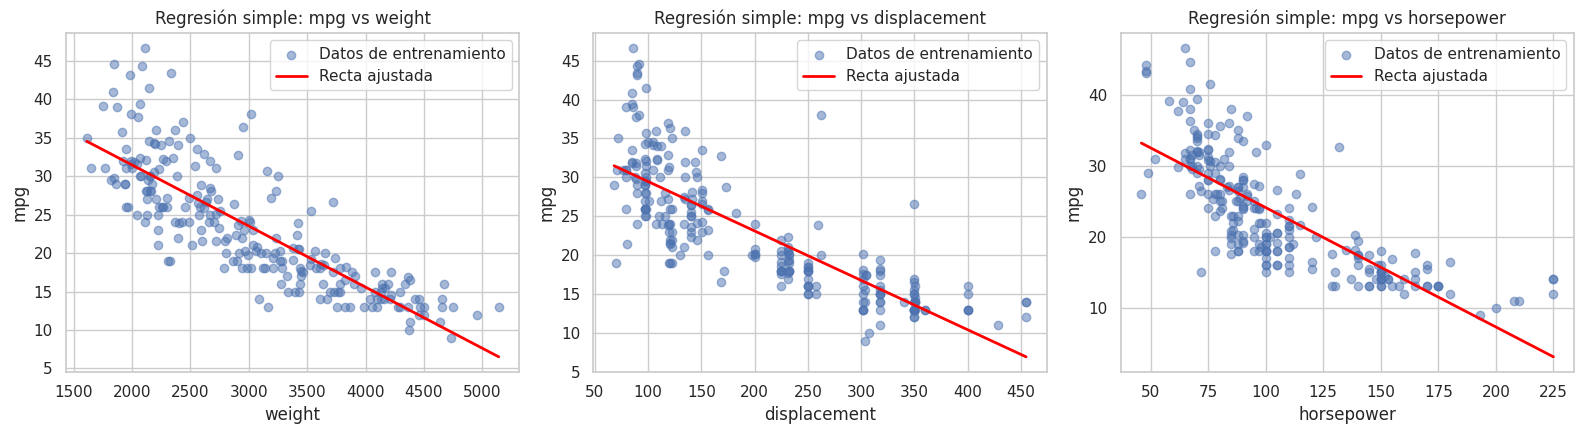

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, var in zip(axes, simples):
    modelo = modelos[f'Simple: {var}'][0]
    x_linea = np.linspace(train[var].min(), train[var].max(), 100)
    y_linea = modelo.predict(pd.DataFrame({var: x_linea}))
    ax.scatter(train[var], train[objetivo], alpha=0.5, label='Datos de entrenamiento')
    ax.plot(x_linea, y_linea, color='red', linewidth=2, label='Recta ajustada')
    ax.set_xlabel(var)
    ax.set_ylabel('mpg')
    ax.set_title(f'Regresión simple: mpg vs {var}')
    ax.legend()

plt.tight_layout()
plt.show()

En los tres gráficos se nota que la recta pasa **por encima** de los puntos en la zona media y **por debajo** en los extremos (carros muy livianos y muy pesados). Es la curvatura que se vio en la exploración: una recta no alcanza a seguirla del todo.

In [19]:
tabla_simples = pd.DataFrame(resultados_val)
print('MÉTRICAS EN VALIDACIÓN – modelos simples')
tabla_simples.round(3)

MÉTRICAS EN VALIDACIÓN – modelos simples


,Modelo,Tipo,Variables,R2,MAE,RMSE
0,Simple: weight,Simple,weight,0.716,3.146,3.769
1,Simple: displacement,Simple,displacement,0.672,3.291,4.051
2,Simple: horsepower,Simple,horsepower,0.587,3.749,4.548


**Selección del mejor modelo simple.** El criterio principal es el **menor RMSE en validación**. Gana el modelo con **`weight`** (RMSE = 3,77 mpg), seguido de `displacement` (4,05) y `horsepower` (4,55). Las otras dos métricas dicen lo mismo: `weight` también tiene el menor MAE (3,15 mpg, o sea que en promedio se equivoca por unas 3 mpg) y el mayor R² (0,72, explica cerca del 72 % de la variación de `mpg` en validación).

## 8. Regresión lineal múltiple

### Revisión de redundancia entre predictores

Antes de armar los modelos se calcula el **VIF** (factor de inflación de la varianza) en entrenamiento. Para cada predictor se ajusta una regresión con los otros cinco y se calcula VIF = 1 / (1 − R²). Un VIF mayor que 10 indica que esa variable se puede explicar casi por completo con las demás, es decir, que su información está repetida.

In [20]:
vif = {}
for col in predictores:
    otros = [c for c in predictores if c != col]
    r2_col = LinearRegression().fit(train[otros], train[col]).score(train[otros], train[col])
    vif[col] = 1 / (1 - r2_col)

pd.Series(vif, name='VIF (entrenamiento)').sort_values(ascending=False).round(2)

,VIF (entrenamiento)
displacement,18.90
cylinders,10.95
weight,9.78
horsepower,8.07
acceleration,2.42
model-year,1.31


**Lectura del VIF:** `displacement` (18,9) y `cylinders` (11,0) pasan de 10, y `weight` (9,8) y `horsepower` (8,1) están muy cerca. Esto confirma lo que mostró la matriz de correlación: esas cuatro variables se pueden predecir casi por completo unas con otras. `acceleration` (2,4) y sobre todo `model-year` (1,3) tienen VIF bajo, o sea que su información no está repetida en las demás.

### Selección de variables del modelo reducido: `weight` + `model-year`

- **`weight`** porque fue el mejor predictor simple y resume la información del grupo tamaño/motor. Meter además `displacement`, `horsepower` o `cylinders` sería repetir casi lo mismo.
- **`model-year`** porque tiene una relación moderada con `mpg` (0,58) y es la variable menos relacionada con el peso (r = −0,32, VIF 1,3). Aporta algo que el peso no explica: los carros más recientes rinden más aunque pesen igual.
- `acceleration` no se incluye porque su relación con `mpg` es débil (0,37) y con mucha dispersión.

El segundo modelo usa **los seis predictores**, como pide la guía, para comparar si agregar todo mejora o no.

In [21]:
grupos_multiples = {
    'Múltiple: weight + model-year': ['weight', 'model-year'],
    'Múltiple: 6 predictores': predictores,
}

for nombre, variables in grupos_multiples.items():
    modelo = LinearRegression()
    modelo.fit(train[variables], train[objetivo])
    modelos[nombre] = (modelo, variables)
    resultados_val.append({'Modelo': nombre, 'Tipo': 'Múltiple', 'Variables': ', '.join(variables),
                           **evaluar(modelo, val[variables], val[objetivo])})

    print(nombre)
    print(f'   Intercepto: {modelo.intercept_:.4f}')
    for v, c in zip(variables, modelo.coef_):
        print(f'   {v:13s} {c:+.5f}')
    print()

Múltiple: weight + model-year
   Intercepto: -16.7558
   weight        -0.00685
   model-year    +0.79890

Múltiple: 6 predictores
   Intercepto: -18.3930
   cylinders     +0.26166
   displacement  -0.00670
   horsepower    +0.00464
   weight        -0.00665
   acceleration  +0.11627
   model-year    +0.78065



**Modelo reducido:** mpg = −16,76 − 0,00685 · weight + 0,799 · model-year

- Si se comparan dos carros **del mismo año**, cada 1.000 lb de más restan unas **6,85 mpg**.
- Si se comparan dos carros **del mismo peso**, cada año más reciente suma unas **0,80 mpg**. Eso refleja las mejoras tecnológicas de la época.
- La pendiente de `weight` bajó un poco frente al modelo simple (de −0,00794 a −0,00685) porque parte de lo que antes se le atribuía al peso en realidad era efecto del año (los carros nuevos también eran más livianos).
- El intercepto (−16,76) no tiene sentido práctico: corresponde a peso 0 y año 0.

**Modelo con 6 predictores:** aquí aparece el efecto de la redundancia. `cylinders` (+0,26) y `horsepower` (+0,005) quedan con **signo positivo**, aunque en la exploración ambas tenían relación negativa con `mpg`. No es que más cilindros mejoren el rendimiento; es que su información ya está metida en `weight` y `displacement`, y el modelo reparte los efectos de forma inestable. Por eso en este modelo los coeficientes de esas variables no se deben interpretar uno por uno.

## 9. Comparación de los cinco modelos en validación

In [22]:
tabla_val = pd.DataFrame(resultados_val)
print('MÉTRICAS EN EL CONJUNTO DE VALIDACIÓN (80 registros)')
tabla_val.round(3)

MÉTRICAS EN EL CONJUNTO DE VALIDACIÓN (80 registros)


,Modelo,Tipo,Variables,R2,MAE,RMSE
0,Simple: weight,Simple,weight,0.716,3.146,3.769
1,Simple: displacement,Simple,displacement,0.672,3.291,4.051
2,Simple: horsepower,Simple,horsepower,0.587,3.749,4.548
3,Múltiple: weight + model-year,Múltiple,"weight, model-year",0.828,2.411,2.935
4,Múltiple: 6 predictores,Múltiple,"cylinders, displacement, horsepower, weight, a...",0.817,2.476,3.024


In [23]:
mejor_simple = tabla_val[tabla_val['Tipo'] == 'Simple'].sort_values('RMSE').iloc[0]['Modelo']
mejor_multiple = tabla_val[tabla_val['Tipo'] == 'Múltiple'].sort_values('RMSE').iloc[0]['Modelo']
print('Mejor modelo simple (menor RMSE en validación):  ', mejor_simple)
print('Mejor modelo múltiple (menor RMSE en validación):', mejor_multiple)

Mejor modelo simple (menor RMSE en validación):   Simple: weight
Mejor modelo múltiple (menor RMSE en validación): Múltiple: weight + model-year


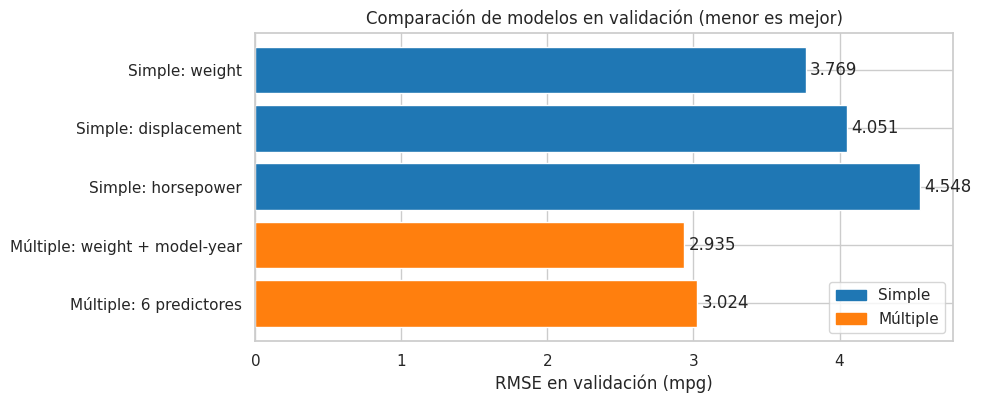

In [24]:
plt.figure(figsize=(9, 4))
colores = ['tab:blue' if t == 'Simple' else 'tab:orange' for t in tabla_val['Tipo']]
plt.barh(tabla_val['Modelo'], tabla_val['RMSE'], color=colores)
for i, v in enumerate(tabla_val['RMSE']):
    plt.text(v + 0.03, i, f'{v:.3f}', va='center')
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color='tab:blue', label='Simple'), Patch(color='tab:orange', label='Múltiple')], loc='lower right')
plt.xlabel('RMSE en validación (mpg)')
plt.title('Comparación de modelos en validación (menor es mejor)')
plt.gca().invert_yaxis()
plt.show()

- **Mejor simple:** `weight` (RMSE 3,77 mpg).
- **Mejor múltiple:** `weight + model-year` (RMSE 2,94 mpg, R² 0,83).
- El modelo con los **6 predictores no mejoró** al de 2: su RMSE es ligeramente mayor (3,02 frente a 2,94). Con solo 80 registros de validación esa diferencia es pequeña y no se debe sobreinterpretar; en la práctica los dos rinden casi igual. Aun así, usar el triple de variables no trae ninguna ganancia, y `cylinders`, `displacement`, `horsepower` y `acceleration` repiten información que ya está en `weight` (VIF altos), con coeficientes inestables. Por **parsimonia y estabilidad** se prefiere el de 2 variables. Esto confirma que más variables no significa automáticamente mejor predicción.
- Cualquiera de los dos múltiples mejora bastante frente a los simples, porque incorporan `model-year`, que trae información que el peso no tiene.

Con esto quedan seleccionados **dos modelos** para la evaluación final: `Simple: weight` y `Múltiple: weight + model-year`. El conjunto de prueba no se usó para escogerlos.

## 10. Evaluación final en el conjunto de prueba

Ahora sí se usa el 20 % de prueba, que se había guardado. Estas métricas son los **resultados finales** y ya no se usan para cambiar ninguna decisión.

In [25]:
resultados_prueba = []
for nombre in [mejor_simple, mejor_multiple]:
    modelo, variables = modelos[nombre]
    resultados_prueba.append({'Modelo': nombre, 'Variables': ', '.join(variables),
                              **evaluar(modelo, test[variables], test[objetivo])})

tabla_prueba = pd.DataFrame(resultados_prueba)
print('RESULTADOS FINALES EN EL CONJUNTO DE PRUEBA (80 registros no usados antes)')
tabla_prueba.round(3)

RESULTADOS FINALES EN EL CONJUNTO DE PRUEBA (80 registros no usados antes)


,Modelo,Variables,R2,MAE,RMSE
0,Simple: weight,weight,0.687,3.517,4.459
1,Múltiple: weight + model-year,"weight, model-year",0.820,2.653,3.381


In [26]:
rmse_simple = tabla_prueba.loc[0, 'RMSE']
rmse_multiple = tabla_prueba.loc[1, 'RMSE']
diferencia = rmse_simple - rmse_multiple

print(f'RMSE en prueba – mejor simple:   {rmse_simple:.3f} mpg')
print(f'RMSE en prueba – mejor múltiple: {rmse_multiple:.3f} mpg')
print(f'Diferencia de RMSE:              {diferencia:.3f} mpg')

if rmse_simple > 0:   # se evita dividir por cero
    print(f'Mejora porcentual: {diferencia / rmse_simple * 100:.1f} % (denominador: RMSE del modelo simple)')

RMSE en prueba – mejor simple:   4.459 mpg
RMSE en prueba – mejor múltiple: 3.381 mpg
Diferencia de RMSE:              1.078 mpg
Mejora porcentual: 24.2 % (denominador: RMSE del modelo simple)


In [27]:
# Validación vs. prueba para los dos modelos seleccionados
comparacion = pd.DataFrame({
    'RMSE validación': tabla_val.set_index('Modelo').loc[[mejor_simple, mejor_multiple], 'RMSE'].values,
    'RMSE prueba': tabla_prueba['RMSE'].values,
}, index=[mejor_simple, mejor_multiple])
comparacion['Cambio'] = comparacion['RMSE prueba'] - comparacion['RMSE validación']
comparacion.round(3)

,RMSE validación,RMSE prueba,Cambio
Simple: weight,3.769,4.459,0.691
Múltiple: weight + model-year,2.935,3.381,0.446


**Comparación del error.** En prueba, el modelo múltiple se equivoca en promedio **3,38 mpg** (RMSE) frente a **4,46 mpg** del simple: una reducción de **1,08 mpg**, que equivale a una **mejora del 24,2 %** tomando como denominador el RMSE del modelo simple. El R² pasa de 0,69 a 0,82 y el MAE de 3,52 a 2,65 mpg.

Los dos modelos empeoran un poco al pasar de validación a prueba (el simple sube 0,69 mpg y el múltiple 0,45 mpg). Es normal: con 80 registros por conjunto, un par de carros difíciles cambia bastante el RMSE. Lo importante es que **el orden se mantiene**: el múltiple sigue siendo claramente mejor.

## 11. Gráficos del modelo recomendado: `weight + model-year`

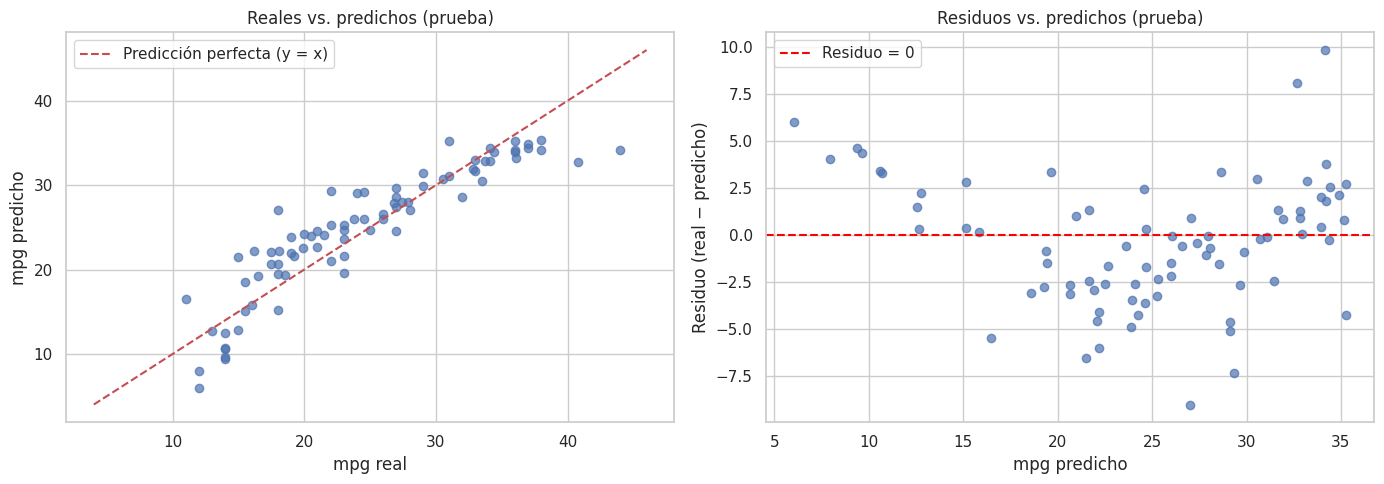

In [28]:
modelo_final, variables_final = modelos[mejor_multiple]
pred_test = modelo_final.predict(test[variables_final])
residuos = test[objetivo] - pred_test

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(test[objetivo], pred_test, alpha=0.7)
lim = [min(test[objetivo].min(), pred_test.min()) - 2, max(test[objetivo].max(), pred_test.max()) + 2]
axes[0].plot(lim, lim, 'r--', label='Predicción perfecta (y = x)')
axes[0].set_xlabel('mpg real')
axes[0].set_ylabel('mpg predicho')
axes[0].set_title('Reales vs. predichos (prueba)')
axes[0].legend()

axes[1].scatter(pred_test, residuos, alpha=0.7)
axes[1].axhline(0, color='red', linestyle='--', label='Residuo = 0')
axes[1].set_xlabel('mpg predicho')
axes[1].set_ylabel('Residuo (real − predicho)')
axes[1].set_title('Residuos vs. predichos (prueba)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [29]:
# Promedio de los residuos por rango de predicción, para ver si hay un patrón
tramos = pd.cut(pred_test, bins=[0, 15, 20, 25, 30, 40])
resumen_residuos = residuos.groupby(tramos, observed=True).agg(['count', 'mean']).round(2)
resumen_residuos.columns = ['n', 'residuo promedio']
resumen_residuos

,n,residuo promedio
"(0, 15]",9,3.31
"(15, 20]",9,-0.76
"(20, 25]",21,-2.51
"(25, 30]",19,-2.05
"(30, 40]",22,1.69


In [30]:
# Los seis errores más grandes en prueba
errores = test[['mpg', 'cylinders', 'weight', 'model-year']].copy()
errores['mpg predicho'] = pred_test
errores['residuo'] = residuos
errores.loc[errores['residuo'].abs().sort_values(ascending=False).index].head(6).round(2)

,mpg,cylinders,weight,model-year,mpg predicho,residuo
394,44.0,4,2130,82,34.16,9.84
111,18.0,3,2124,73,27.01,-9.01
324,40.8,4,2110,80,32.70,8.10
389,22.0,6,2835,82,29.33,-7.33
155,15.0,6,3158,75,21.52,-6.52
42,12.0,8,4955,71,6.01,5.99


**Qué se ve en los gráficos:**

- **Reales vs. predichos:** la mayoría de los puntos queda cerca de la línea roja, pero se abren en los extremos. Los carros con mayor rendimiento real (por encima de unos 35 mpg) tienden a quedar **por debajo** de la línea: el modelo les predice menos de lo que realmente rinden.
- **Residuos vs. predichos:** los residuos no están repartidos al azar alrededor de cero, forman una **U**. Cuando el modelo predice menos de 15 mpg el residuo promedio es +3,3 (subestima a los carros pesados), entre 20 y 30 mpg es negativo (−2,5 y −2,1, sobreestima) y por encima de 30 vuelve a ser positivo (+1,7). Esa U es la huella de la relación **curva** entre peso y `mpg` que una ecuación lineal no puede seguir. También se ve que la dispersión de los residuos crece un poco en los predichos altos.
- **Errores grandes:** el peor caso es un carro de 1982 de 44 mpg al que el modelo le predice 34,2 (se queda corto por 9,8 mpg). Otro es un carro de **3 cilindros** de 1973 que pesa solo 2.124 lb pero rinde 18 mpg; el modelo, guiándose por el peso, le predice 27 mpg. Son carros con características que el peso y el año no capturan (por ejemplo, un tipo de motor poco común).
- En la sexta fila el modelo predice solo 6 mpg para un carro de 4.955 lb que en realidad rinde 12: la recta sigue bajando sin límite, mientras que en la realidad el `mpg` de los carros pesados se aplana.

**Límites de la aproximación lineal:** el modelo supone que cada libra o cada año cambia el `mpg` siempre en la misma cantidad, y los datos muestran que no es así en los extremos. Funciona bien en la zona media, pero comete errores sistemáticos en carros muy livianos y muy pesados.

### Conclusión de las regresiones y preguntas de reflexión

**¿Incorporar variables mejoró la predicción? ¿Vale la pena la complejidad?** Sí. Pasar de `weight` solo a `weight + model-year` bajó el RMSE de prueba de 4,46 a 3,38 mpg (−24,2 %), y la mejora ya se veía en validación. El costo es mínimo: es una sola variable más, fácil de conseguir y de interpretar. En cambio, pasar de 2 a 6 variables **no** se justifica: el modelo de 6 predictores no mejoró en validación (RMSE 3,02 frente a 2,94, una diferencia pequeña) y además sus coeficientes son difíciles de interpretar por la redundancia. Para decidir no se usó el R² de entrenamiento, sino el RMSE de validación, y la prueba confirmó la decisión.

**¿El mejor resultado de validación se mantuvo en prueba?** Sí en el orden: el múltiple sigue siendo mejor que el simple por más de 1 mpg. Los valores exactos empeoraron un poco (de 2,94 a 3,38 en el múltiple), lo cual es esperable con conjuntos de 80 registros.

**¿Qué limitaciones tiene predecir vehículos fuera de los rangos observados?** El modelo solo vio carros de 1.613 a 5.140 lb y de los años 1970 a 1982. Fuera de ese rango la recta se sigue extendiendo sin control: para un carro de 1990 sumaría 0,8 mpg por cada año como si la tecnología mejorara siempre al mismo ritmo, y para un carro muy pesado podría dar valores irreales (incluso negativos). Además, los carros actuales tienen tecnologías (inyección, híbridos, eléctricos) que no existen en la base. Por eso el modelo no se debe usar para extrapolar.

**¿Se puede afirmar que una variable causa cambios en `mpg`?** No con este análisis. Los datos son observacionales y las variables están mezcladas entre sí. Los coeficientes indican asociación "manteniendo las otras variables del modelo constantes", pero puede haber factores que no están en la base (aerodinámica, tipo de transmisión, normas de emisiones) que expliquen parte de la relación. Que físicamente tenga sentido que el peso afecte el consumo no convierte al coeficiente en una medida causal.

## 12. ANOVA de una vía: ¿el `mpg` medio difiere entre carros de 4, 6 y 8 cilindros?

Para este análisis se usan **todas** las observaciones con `mpg` y `cylinders` válidos (no hace falta la división de la regresión). Los grupos se definen **antes** de calcular el ANOVA: 4, 6 y 8 cilindros. Los carros de 3 y 5 cilindros se excluyen **solo de esta comparación** porque son muy pocos (4 y 3) para estimar bien la media de un grupo; siguen dentro de las regresiones.

In [31]:
datos_anova = df[['mpg', 'cylinders']].dropna()
datos_anova = datos_anova[datos_anova['cylinders'].isin([4, 6, 8])]
print('Registros usados en el ANOVA:', len(datos_anova), 'de', len(df))

descriptivos = datos_anova.groupby('cylinders')['mpg'].agg(n='count', media='mean', desviacion_estandar='std')
descriptivos.round(2)

Registros usados en el ANOVA: 391 de 398


,n,media,desviacion_estandar
cylinders,,,
4,204,29.29,5.71
6,84,19.99,3.81
8,103,14.96,2.84


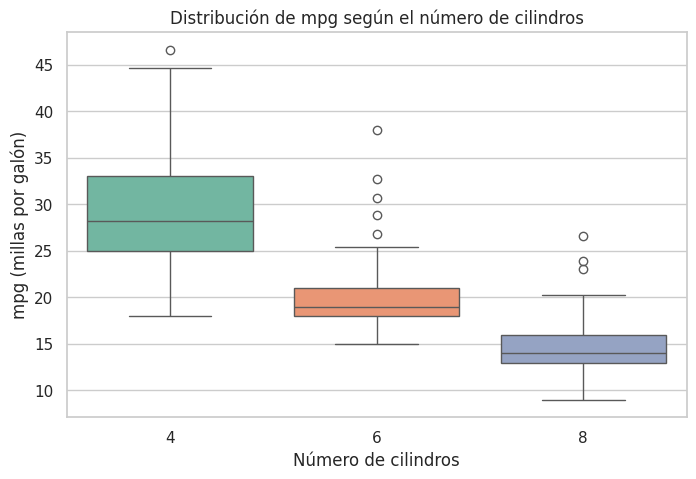

In [32]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=datos_anova, x='cylinders', y='mpg', hue='cylinders', palette='Set2', legend=False)
plt.xlabel('Número de cilindros')
plt.ylabel('mpg (millas por galón)')
plt.title('Distribución de mpg según el número de cilindros')
plt.show()

Los carros de 4 cilindros rinden en promedio **29,3 mpg**, los de 6 cilindros **20,0 mpg** y los de 8 cilindros **15,0 mpg**. En el boxplot las cajas de los tres grupos no se traslapan; solo se cruzan los bigotes y algunos atípicos. También se ve que la dispersión cambia bastante: el grupo de 4 cilindros es el más disperso (desviación 5,71) y el de 8 el más compacto (2,84).

### Hipótesis (nivel de significancia α = 0,05)

- **H₀:** μ₄ = μ₆ = μ₈ (el `mpg` medio es igual en los tres grupos).
- **H₁:** al menos una de las medias es diferente.

### Revisión de supuestos

**1. Independencia.** Cada fila es un vehículo distinto (modelo y año) y la medición de uno no depende de la de otro, así que el supuesto es razonable. La única salvedad es que algunos modelos se repiten en varios años con características casi iguales, lo que puede generar algo de dependencia entre registros del mismo fabricante.

In [33]:
# 2. Normalidad por grupo: prueba de Shapiro-Wilk (H0: los datos vienen de una distribución normal)
print('Prueba de Shapiro-Wilk por grupo')
for c in [4, 6, 8]:
    grupo = datos_anova.loc[datos_anova['cylinders'] == c, 'mpg']
    w, p = stats.shapiro(grupo)
    conclusion = 'NO se rechaza normalidad' if p >= 0.05 else 'se rechaza normalidad'
    print(f'{c} cilindros: W = {w:.4f}, p = {p:.2e} -> {conclusion}')

Prueba de Shapiro-Wilk por grupo
4 cilindros: W = 0.9757, p = 1.32e-03 -> se rechaza normalidad
6 cilindros: W = 0.8234, p = 1.28e-08 -> se rechaza normalidad
8 cilindros: W = 0.9246, p = 1.90e-05 -> se rechaza normalidad


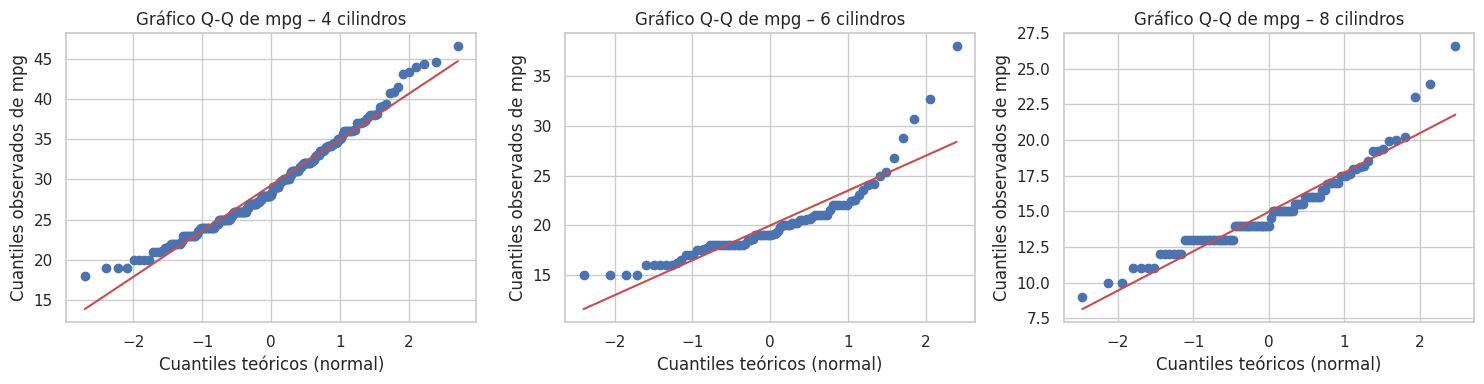

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, [4, 6, 8]):
    stats.probplot(datos_anova.loc[datos_anova['cylinders'] == c, 'mpg'], dist='norm', plot=ax)
    ax.set_title(f'Gráfico Q-Q de mpg – {c} cilindros')
    ax.set_xlabel('Cuantiles teóricos (normal)')
    ax.set_ylabel('Cuantiles observados de mpg')
plt.tight_layout()
plt.show()

In [35]:
# 3. Homogeneidad de varianzas: prueba de Levene (H0: las varianzas son iguales)
grupos = [datos_anova.loc[datos_anova['cylinders'] == c, 'mpg'] for c in [4, 6, 8]]
estad_lev, p_lev = stats.levene(*grupos)
print(f'Levene: estadístico = {estad_lev:.4f}, p = {p_lev:.2e}')
print('Conclusión:', 'varianzas homogéneas' if p_lev >= 0.05 else 'las varianzas NO son homogéneas')

Levene: estadístico = 28.3143, p = 3.33e-12
Conclusión: las varianzas NO son homogéneas


**Resultado de los supuestos:**

- **Normalidad:** Shapiro-Wilk rechaza la normalidad en los tres grupos (todos los p < 0,05). En los gráficos Q-Q los puntos se separan de la línea en las colas, sobre todo en el grupo de 6 cilindros (W = 0,82), que tiene algunos carros con `mpg` alto. Hay que tener en cuenta que con grupos grandes (84 a 204 carros) Shapiro detecta hasta desviaciones pequeñas, y el ANOVA es bastante tolerante a la falta de normalidad cuando los grupos son grandes.
- **Homogeneidad de varianzas:** Levene también rechaza (p ≈ 3,3 × 10⁻¹²). La varianza del grupo de 4 cilindros es unas cuatro veces la del grupo de 8 (5,71² frente a 2,84²) y los grupos tienen tamaños distintos. Este supuesto es el que más afecta al ANOVA clásico.

Conclusión de esta parte: **los supuestos no se cumplen bien**, así que el resultado del ANOVA se va a leer con cautela.

In [36]:
f_estad, p_valor = stats.f_oneway(*grupos)
print(f'ANOVA de una vía: F = {f_estad:.2f}, p = {p_valor:.2e}')

alfa = 0.05
if p_valor < alfa:
    print(f'p < {alfa}: se rechaza H0. Hay evidencia de que al menos una media de mpg es diferente.')
else:
    print(f'p >= {alfa}: no se rechaza H0. No hay evidencia suficiente de diferencias entre medias.')

ANOVA de una vía: F = 345.12, p = 7.70e-87
p < 0.05: se rechaza H0. Hay evidencia de que al menos una media de mpg es diferente.


### Conclusión del ANOVA

Con **F = 345,12** y un valor **p ≈ 7,7 × 10⁻⁸⁷** (muchísimo menor que 0,05), **se rechaza la hipótesis nula**: hay evidencia de que el rendimiento medio de combustible no es igual en los carros de 4, 6 y 8 cilindros.

Ahora, hay que poner este resultado en su contexto:

- **Los supuestos no se cumplen del todo** (no normalidad y varianzas distintas), así que el valor p del ANOVA clásico no se debe tomar como exacto ni como evidencia concluyente por sí solo. Lo que sí respalda la conclusión es que las diferencias entre medias son muy grandes (29,3 vs. 20,0 vs. 15,0 mpg) comparadas con la dispersión de cada grupo, y el boxplot lo muestra claramente.
- **El ANOVA no dice cuáles grupos difieren entre sí**, solo que al menos uno es distinto. Para afirmar que, por ejemplo, 6 y 8 cilindros son diferentes haría falta una prueba de comparaciones por pares, que no hace parte de esta práctica.
- **No permite hablar de causalidad.** Es un estudio observacional: los carros de 8 cilindros también son más pesados, más potentes y en su mayoría más viejos, así que la diferencia de `mpg` no se le puede atribuir solo al número de cilindros.

## 13. Conclusión general

1. **Preparación.** La base venía casi limpia. Solo hubo que imputar 2 valores faltantes de `horsepower` con la mediana del entrenamiento; no hubo duplicados ni inconsistencias, y los atípicos se conservaron porque son carros reales.
2. **Selección de variables.** `weight`, `displacement`, `horsepower` y `cylinders` están fuertemente correlacionadas con `mpg`, pero también entre sí (VIF altos), así que en el fondo cuentan la misma historia: el tamaño del carro y su motor. `model-year` aporta información distinta (el avance tecnológico).
3. **Comparación de regresiones.** El mejor modelo simple fue `weight` (RMSE de validación 3,77) y el mejor múltiple fue `weight + model-year` (2,94). En prueba, el múltiple se equivocó en promedio 3,38 mpg frente a 4,46 del simple, una mejora del 24,2 %. El modelo con los 6 predictores no superó al de 2 (diferencia pequeña, pero sin ninguna ganancia que justifique la complejidad), lo que muestra que **escoger bien las variables importa más que meter muchas**. El modelo recomendado es `weight + model-year`.
4. **ANOVA.** Hay evidencia de que el `mpg` medio difiere entre carros de 4, 6 y 8 cilindros (F = 345,12, p < 0,05), con medias de 29,3, 20,0 y 15,0 mpg. Como la normalidad y la igualdad de varianzas no se cumplen, el resultado se interpreta con cautela, aunque la diferencia es tan grande que se ve a simple vista.
5. **Limitaciones.** La relación entre peso y `mpg` es curva, por eso los residuos forman una U y el modelo lineal se equivoca de forma sistemática en los carros muy livianos y muy pesados. El modelo no sirve para carros fuera del rango 1970–1982 ni fuera del rango de pesos observado, y ninguno de los análisis permite concluir causalidad, porque los datos son observacionales.